In [1]:
import pandas as pd
df=pd.read_csv('Titanic-Dataset.csv')
df.head(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C


In [2]:
df.shape

(891, 12)

In [3]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [4]:
df.duplicated().sum()

0

In [5]:
df['Cabin'].value_counts()

Cabin
B96 B98        4
G6             4
C23 C25 C27    4
C22 C26        3
F33            3
              ..
E34            1
C7             1
C54            1
E36            1
C148           1
Name: count, Length: 147, dtype: int64

In [6]:
print(df['Age'])

0      22.0
1      38.0
2      26.0
3      35.0
4      35.0
       ... 
886    27.0
887    19.0
888     NaN
889    26.0
890    32.0
Name: Age, Length: 891, dtype: float64


In [7]:
print(df['Cabin'])

0       NaN
1       C85
2       NaN
3      C123
4       NaN
       ... 
886     NaN
887     B42
888     NaN
889    C148
890     NaN
Name: Cabin, Length: 891, dtype: object


In [8]:
import numpy as np
df['Age']=df['Age'].replace(np.nan,df["Age"].median())
from sklearn.impute import SimpleImputer
im=SimpleImputer(strategy='most_frequent')
df['Cabin']=im.fit_transform(df[['Cabin']]).ravel()

In [9]:
df['Cabin'].value_counts()

Cabin
B96 B98        691
G6               4
C23 C25 C27      4
C22 C26          3
F33              3
              ... 
E34              1
C7               1
C54              1
E36              1
C148             1
Name: count, Length: 147, dtype: int64

In [10]:
df['Age'].isnull().sum()

0

In [11]:
df.sample(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
632,633,1,1,"Stahelin-Maeglin, Dr. Max",male,32.0,0,0,13214,30.500,B50,C
184,185,1,3,"Kink-Heilmann, Miss. Luise Gretchen",female,4.0,0,2,315153,22.025,B96 B98,S


In [12]:
col=['PassengerId','Name','Ticket','Cabin','Fare']
for c in col:
    df=df.drop(columns=c)

In [13]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df['Embarked']=le.fit_transform(df['Embarked'])
df['Sex']=le.fit_transform(df['Sex'])

In [14]:
X=df.drop(columns="Survived")
y=df['Survived']

In [15]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [16]:
X_train.shape

(712, 6)

In [17]:
from sklearn.tree import DecisionTreeClassifier
dc=DecisionTreeClassifier(max_depth=4)
dc.fit(X_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,4
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [18]:
model=dc.predict(X_test)

In [19]:
from sklearn.metrics import accuracy_score
ac=accuracy_score(y_test,model)
print(ac)

0.8044692737430168


In [20]:
from sklearn.metrics import classification_report,confusion_matrix
cm=confusion_matrix(y_test,model)
print(cm)
print(classification_report(y_test,model))


[[95 10]
 [25 49]]
              precision    recall  f1-score   support

           0       0.79      0.90      0.84       105
           1       0.83      0.66      0.74        74

    accuracy                           0.80       179
   macro avg       0.81      0.78      0.79       179
weighted avg       0.81      0.80      0.80       179



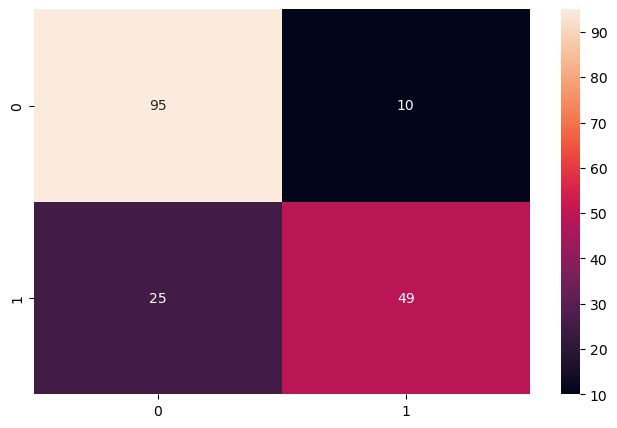

In [21]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
import seaborn as sns
sns.heatmap(confusion_matrix(y_test,model),annot=True,fmt='d')
plt.show(
)

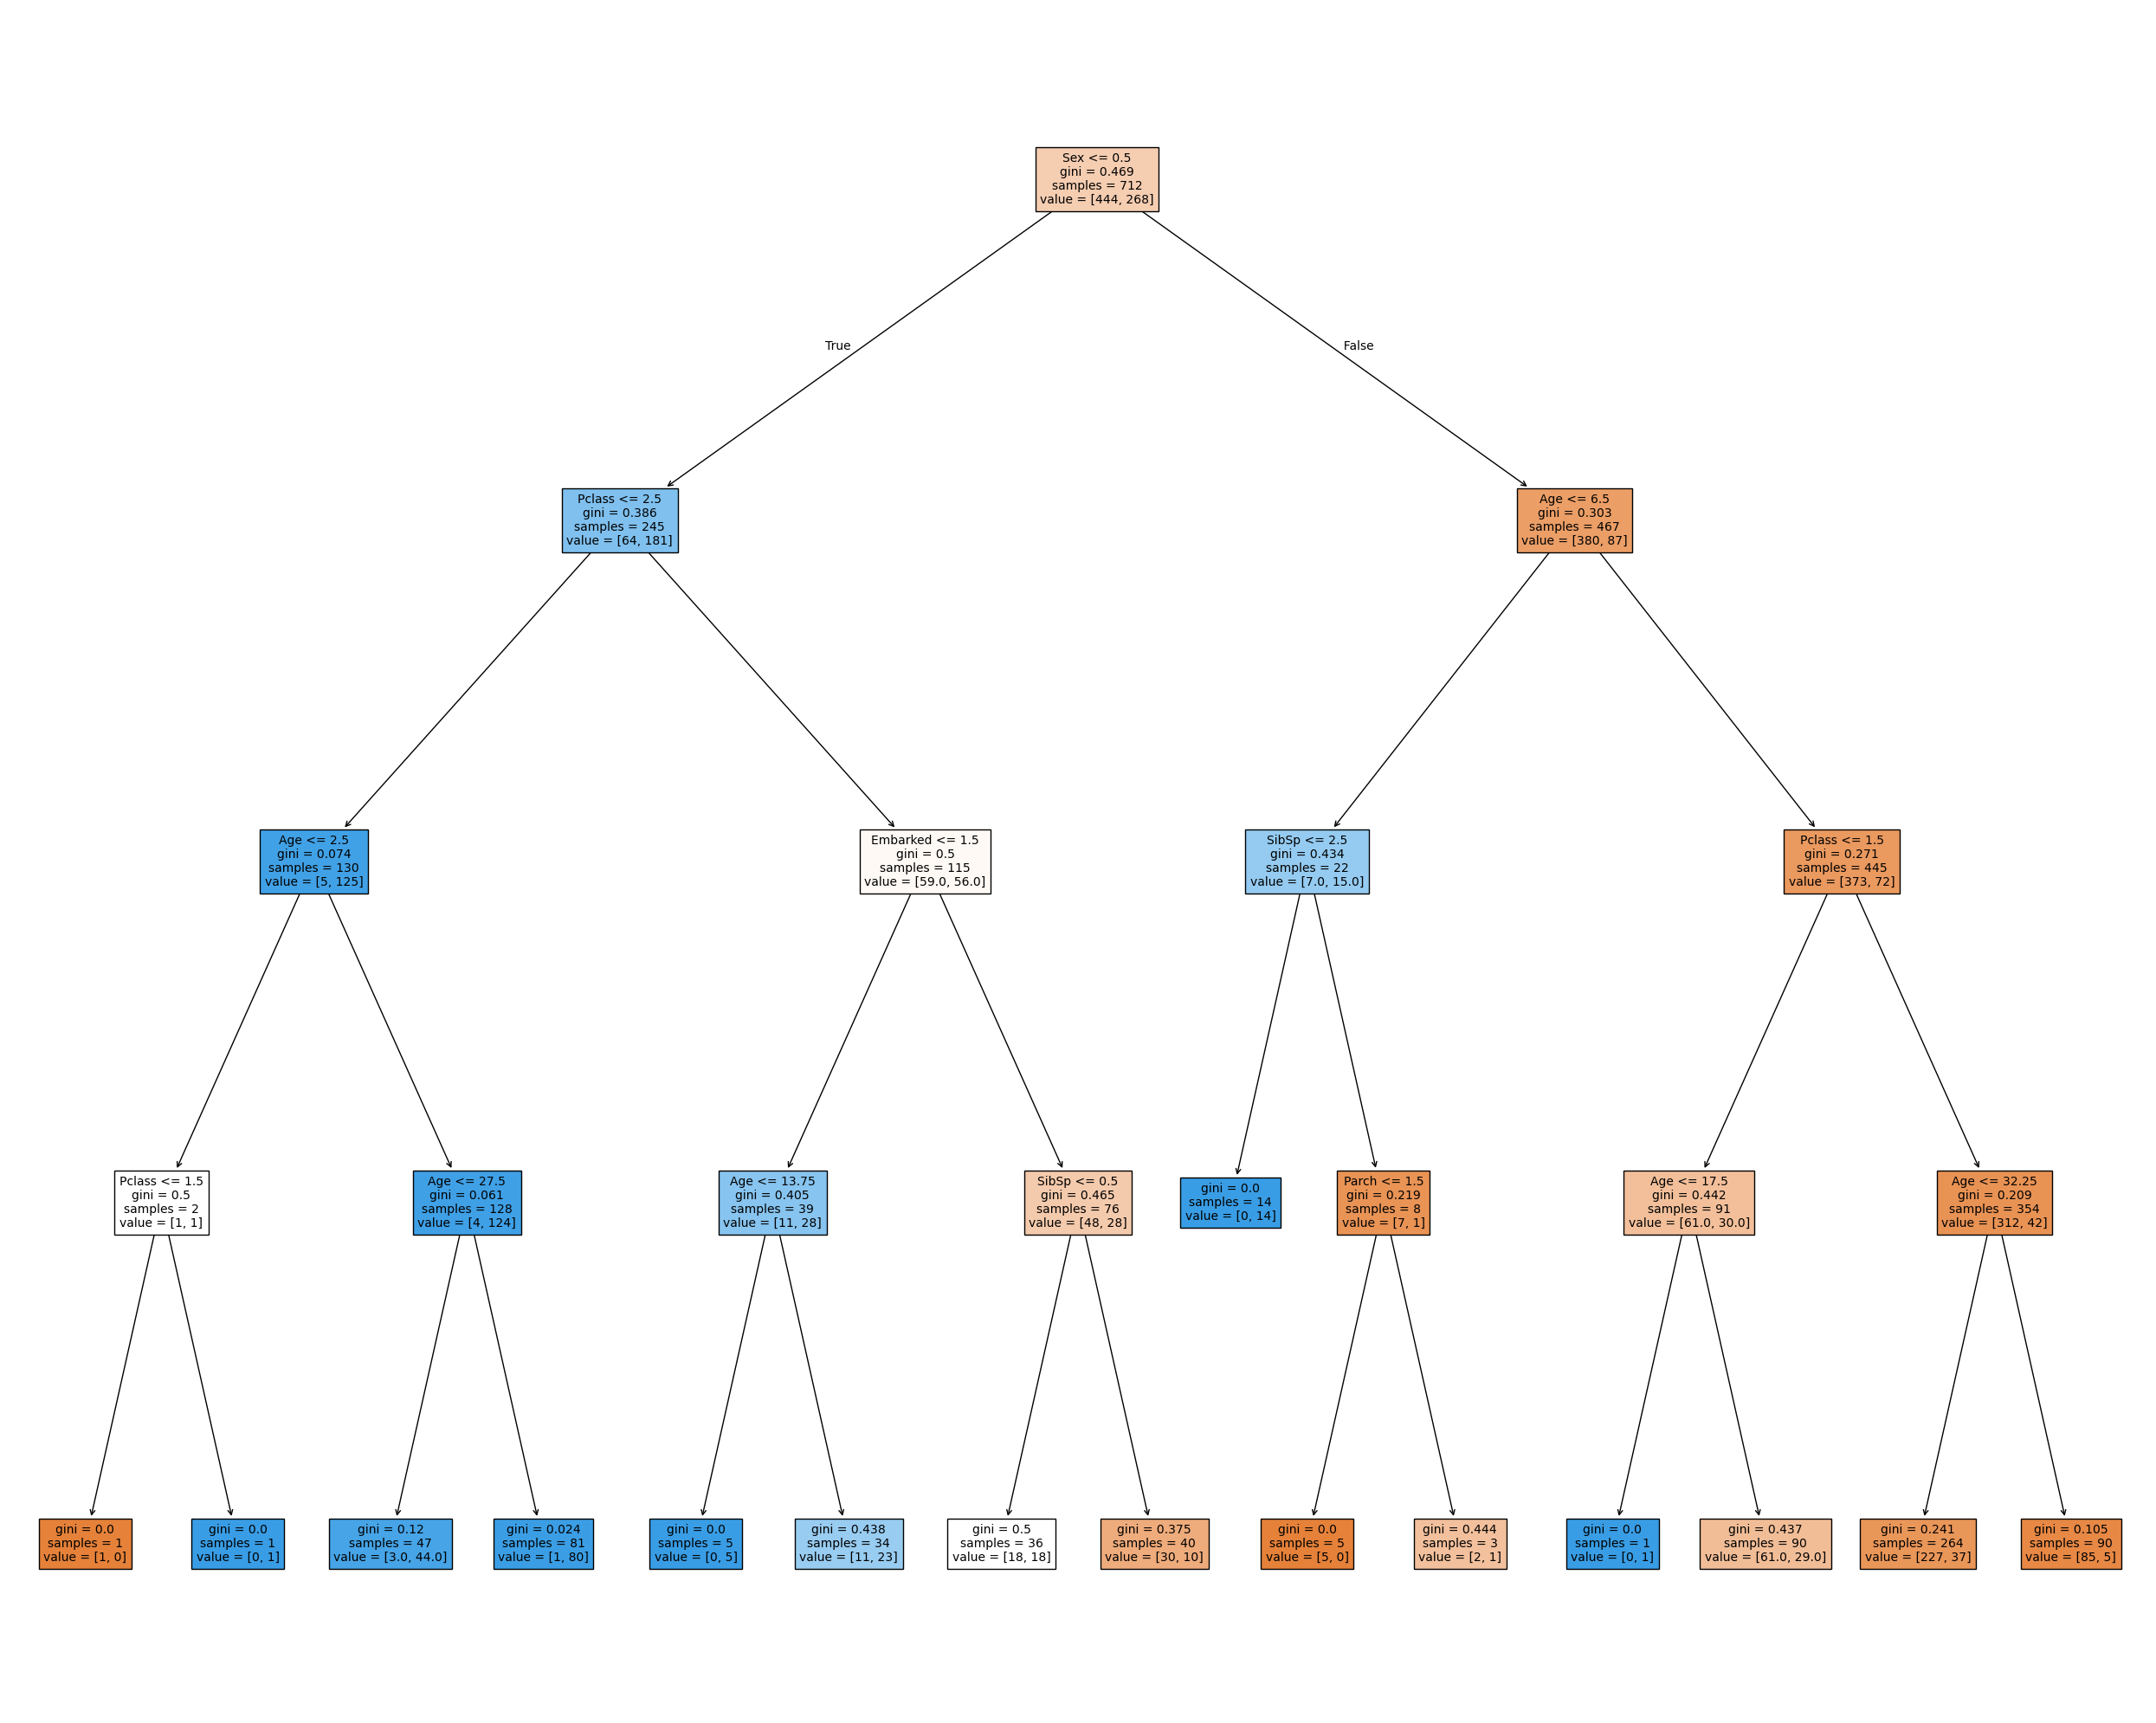

In [24]:
plt.figure(figsize=(25,20))
from sklearn.tree import plot_tree
plot_tree(dc,filled=True,feature_names=X.columns,fontsize=10)
plt.tight_layout()
plt.show()

import libraries

read data set, data preprocessing

missin values handle

remove unnecessary columns

encoding

normalization

train,test,split

model training

prediction

metrics calculation

classification report

confusion matrix

plot decision tree

input sample data and test